# Exercise 11 – Following a Metropolis walker on a rugged landscape

**Week 3 · Monte Carlo and optimisation of clusters**

A long 1D potential with six wells of different depths, decorated with small
cosine ripples. We follow individual Metropolis steps (the "Monte Carlo time")
and then see how far longer walks get at different temperatures.

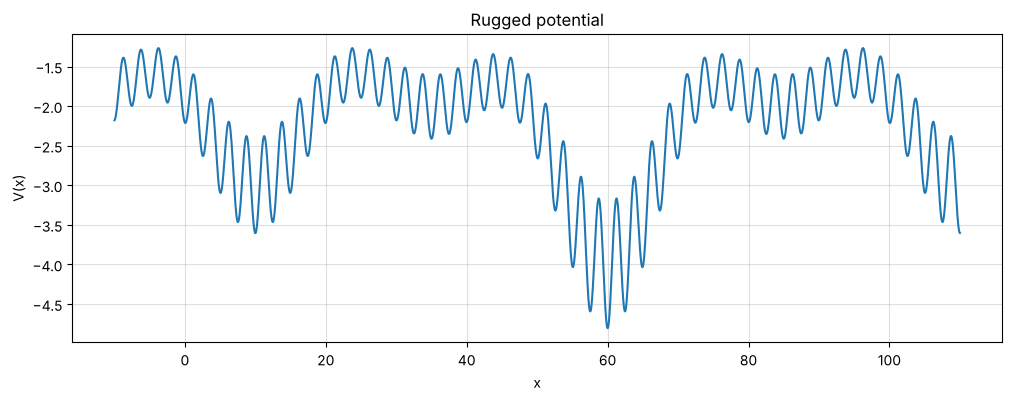

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from comphy.montecarlo import metropolis

rng = np.random.default_rng(1)


def V(x):
    x = np.asarray(x, dtype=float)
    wells = (-1 - np.exp(-(((x + 15) / 10) ** 2)) - 2 * np.exp(-(((x - 10) / 10) ** 2))
             - np.exp(-(((x - 35) / 10) ** 2)) - 3 * np.exp(-(((x - 60) / 10) ** 2))
             - np.exp(-(((x - 85) / 10) ** 2)) - 2 * np.exp(-(((x - 110) / 10) ** 2)))
    return wells * (1 + 0.2 * np.cos(2 * np.pi / 2.5 * x))


xs = np.linspace(-10, 110, 3000)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(xs, V(xs))
ax.set(xlabel="x", ylabel="V(x)", title="Rugged potential")
ax.grid(True, alpha=0.4)
plt.show()

## Ten Metropolis steps
Top: position against Monte Carlo time. Bottom: the visited points on the
potential (colour = time).

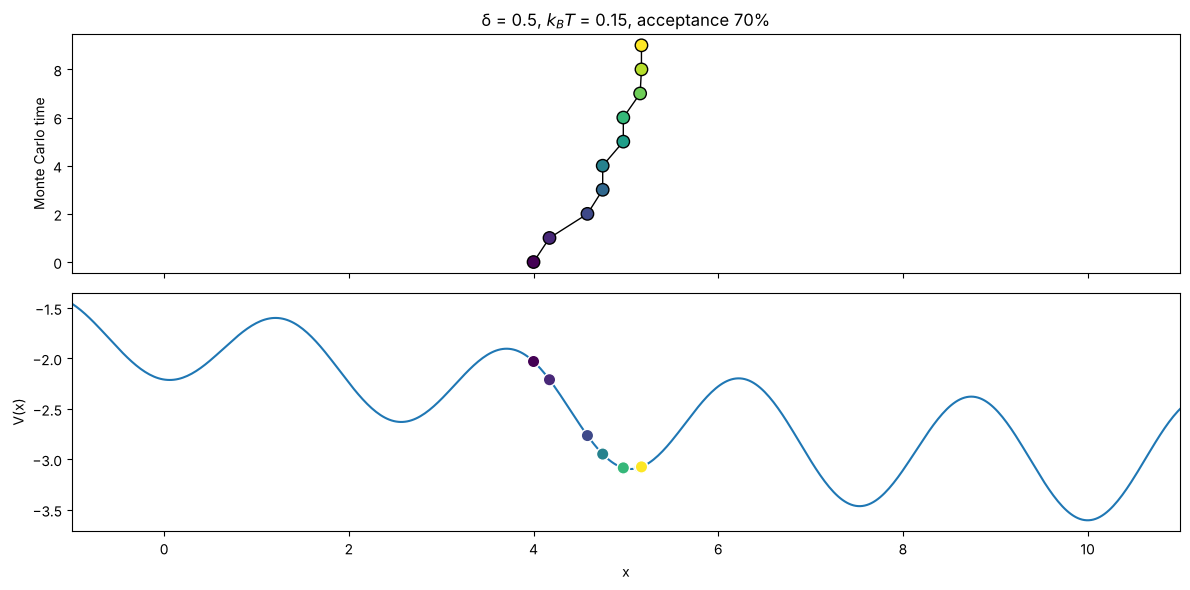

In [2]:
chain, acc = metropolis(V, kT=0.15, x0=4.0, n_steps=10, step=0.5, rng=rng)
colors = plt.cm.viridis(np.linspace(0, 1, len(chain)))

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(chain, np.arange(len(chain)), color="black", lw=1)
axes[0].scatter(chain, np.arange(len(chain)), c=colors, s=80, edgecolor="black", zorder=3)
axes[0].set(ylabel="Monte Carlo time", title=f"δ = 0.5, $k_BT$ = 0.15, acceptance {acc:.0%}")
x_zoom = np.linspace(-1, 11, 500)
axes[1].plot(x_zoom, V(x_zoom))
axes[1].scatter(chain, V(chain), c=colors, s=80, edgecolor="white", zorder=3)
axes[1].set(xlabel="x", ylabel="V(x)", xlim=(-1, 11))
fig.tight_layout()
plt.show()

## Longer walks
20 000 steps for three combinations of temperature and step size. Dotted
lines mark the centres of the large wells.

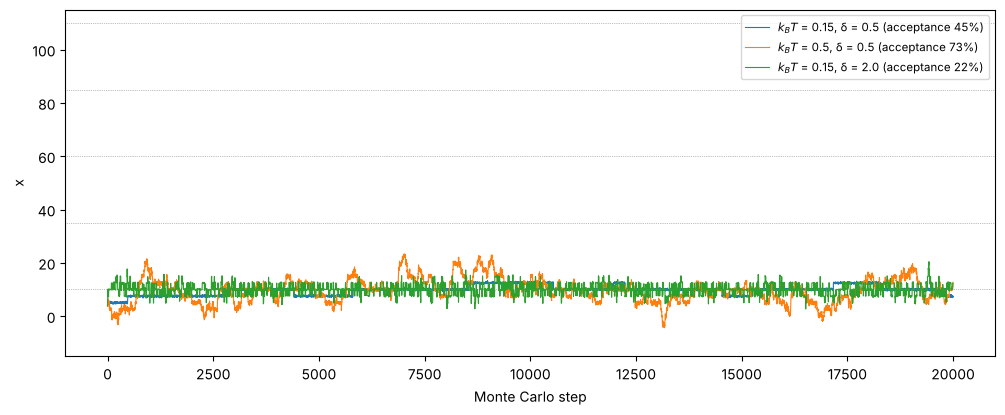

In [3]:
fig, ax = plt.subplots(figsize=(12, 4.5))
for kT, step in [(0.15, 0.5), (0.5, 0.5), (0.15, 2.0)]:
    chain, acc = metropolis(V, kT=kT, x0=4.0, n_steps=20_000, step=step, rng=rng)
    ax.plot(chain, lw=0.8, label=f"$k_BT$ = {kT}, δ = {step} (acceptance {acc:.0%})")
ax.set(xlabel="Monte Carlo step", ylabel="x", ylim=(-15, 115))
for x_min in [-15, 10, 35, 60, 85, 110]:
    ax.axhline(x_min, color="gray", lw=0.5, ls=":")
ax.legend(fontsize="small")
plt.show()

None of the walkers leaves the large well around $x = 10$ in 20 000 steps.
A higher temperature lets the walker explore that well more widely, and
larger steps hop over the small ripples, but the barriers between the large
wells – and the deepest well at $x = 60$ – are out of reach. Rugged
landscapes like this call for better strategies, such as simulated annealing
(exercise 28) or global optimisation (week 7).